### Население WorldPop в радиусе 300м вокруг точек (Вашингтон, округ Колумбия)

In [1]:
import os
import requests
import rasterio
from rasterio.windows import from_bounds
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
from rasterstats import zonal_stats

- Подготовка

In [8]:
# Ссылка на растр WorldPop (США, 2024, constrained, 100м)
# Если ссылка не работает — актуальный файл ищите на:
# https://hub.worldpop.org/geodata/listing?id=100 (выбрать USA и год 2024)
RASTER_URL = "https://data.worldpop.org/GIS/Population/Global_2015_2030/R2024B/2024/USA/v1/100m/constrained/usa_pop_2024_CN_100m_R2024B_v1.tif"

RASTER_FULL_PATH = "../../data_additional/usa_pop_2024_CN_100m_R2024B_v1.tif"   # куда сохранить растр по всей стране
RASTER_CLIPPED_PATH = "../../data_additional/dc_pop_2024.tif"                    # обрезанный растр по округу Колумбия

# Bounding box округа Колумбия: (lon_min, lat_min, lon_max, lat_max)
DC_BBOX = (-77.12, 38.79, -76.90, 38.995)

POINTS_CSV = "../../data_additional/station_list.csv"          # ваш файл с ~1000 точками
LON_COL = "start_lng"
LAT_COL = "start_lat"
RADIUS_M = 300

OUTPUT_CSV = '../../data_additional/population_300.csv'
NODATA_VALUE = -99999    

- Скачивание растра WorldPop
- файл лучше скачать - https://data.worldpop.org/GIS/Population/Global_2015_2030/R2024B/2024/USA/v1/100m/constrained/usa_pop_2024_CN_100m_R2024B_v1.tif

- Обрезка по округу Колумбия

- Работа с маленьким локальным файлом вместо растра на всю страну
значительно ускоряет подсчёт для 1000 точек.

In [9]:
def clip_raster_to_bbox(src_path: str, dst_path: str, bbox: tuple):
    """bbox = (lon_min, lat_min, lon_max, lat_max)"""
    with rasterio.open(src_path) as src:
        window = from_bounds(*bbox, transform=src.transform)
        transform = src.window_transform(window)
        data = src.read(1, window=window)

        profile = src.profile
        profile.update({
            "height": data.shape[0],
            "width": data.shape[1],
            "transform": transform
        })

        with rasterio.open(dst_path, "w", **profile) as dst:
            dst.write(data, 1)

    print("Обрезанный растр сохранён:", dst_path)

clip_raster_to_bbox(RASTER_FULL_PATH, RASTER_CLIPPED_PATH, DC_BBOX)

Обрезанный растр сохранён: ../../data_additional/dc_pop_2024.tif


C:\Users\lenov\AppData\Local\Temp\ipykernel_26724\2488644074.py:6: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  data = src.read(1, window=window)


- Загрузка точек

In [10]:
def load_points(csv_path: str, lon_col, lat_col) -> gpd.GeoDataFrame:
    df = pd.read_csv(csv_path)
    geometry = [Point(xy) for xy in zip(df[lon_col], df[lat_col])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")
    return gdf

points = load_points(POINTS_CSV, LON_COL, LAT_COL)
points

,station_id,station_name,start_lat,start_lng,geometry
0,30200,9th St & Pennsylvania Ave NW,38.894280,-77.023979,POINT (-77.02398 38.89428)
1,30201,9th & G St NW,38.898097,-77.023924,POINT (-77.02392 38.8981)
2,31000,Eads St & 15th St S,38.858971,-77.053230,POINT (-77.05323 38.85897)
3,31001,18th St & S Eads St,38.857250,-77.053320,POINT (-77.05332 38.85725)
4,31002,Crystal Dr & 20th St S,38.856425,-77.049232,POINT (-77.04923 38.85642)
...,...,...,...,...,...
908,32608,Falls Church City Hall / Park Ave & Little Fal...,38.885434,-77.173605,POINT (-77.1736 38.88543)
909,32609,W Columbia St & N Washington St,38.885621,-77.166917,POINT (-77.16692 38.88562)
910,32900,Motivate BX Tech office,38.964406,-77.010759,POINT (-77.01076 38.96441)
911,32901,6035 Warehouse,38.963810,-77.010266,POINT (-77.01027 38.96381)


- Построение буферов 300м

- Буферы строятся в локальной метрической проекции (UTM), подобранной
- автоматически по центроиду точек, — иначе радиус будет неточным.

In [11]:
def buffer_points_meters(gdf: gpd.GeoDataFrame, radius_m: float = 300) -> gpd.GeoDataFrame:
    utm_crs = gdf.estimate_utm_crs()
    gdf_proj = gdf.to_crs(utm_crs)
    gdf_proj["geometry"] = gdf_proj.geometry.buffer(radius_m)
    gdf_buffered = gdf_proj.to_crs("EPSG:4326")
    return gdf_buffered

buffers = buffer_points_meters(points, RADIUS_M)
buffers.head()

,station_id,station_name,start_lat,start_lng,geometry
0,30200,9th St & Pennsylvania Ave NW,38.894280,-77.023979,"POLYGON ((-77.02052 38.89434, -77.02053 38.894..."
1,30201,9th & G St NW,38.898097,-77.023924,"POLYGON ((-77.02047 38.89816, -77.02048 38.897..."
2,31000,Eads St & 15th St S,38.858971,-77.053230,"POLYGON ((-77.04977 38.85903, -77.04978 38.858..."
3,31001,18th St & S Eads St,38.857250,-77.053320,"POLYGON ((-77.04986 38.85731, -77.04987 38.857..."
4,31002,Crystal Dr & 20th St S,38.856425,-77.049232,"POLYGON ((-77.04578 38.85649, -77.04579 38.856..."


- подсчёт населения внутри каждого буфера

In [12]:
def population_in_buffers(gdf_buffered: gpd.GeoDataFrame, raster_path: str, nodata=-99999) -> pd.Series:
    stats = zonal_stats(
        gdf_buffered.geometry,
        raster_path,
        stats=["sum"],
        nodata=nodata,
        all_touched=False
    )
    print(stats)
    return pd.Series([s["sum"] if s["sum"] is not None else 0 for s in stats])

population = population_in_buffers(buffers, RASTER_FULL_PATH, NODATA_VALUE)
population.describe()

[{'sum': 343.95458984375}, {'sum': 629.4727172851562}, {'sum': 7098.125}, {'sum': 5140.5927734375}, {'sum': 1980.399169921875}, {'sum': 2541.1181640625}, {'sum': 2193.0439453125}, {'sum': 2436.552734375}, {'sum': 3064.364501953125}, {'sum': 3064.364501953125}, {'sum': 4812.21533203125}, {'sum': 1222.938232421875}, {'sum': 941.29052734375}, {'sum': 1782.3193359375}, {'sum': 1909.66845703125}, {'sum': 2077.173828125}, {'sum': 2100.4794921875}, {'sum': 2100.4794921875}, {'sum': 4424.51220703125}, {'sum': 4424.51220703125}, {'sum': 4758.634765625}, {'sum': 4639.43310546875}, {'sum': 5928.064453125}, {'sum': 1898.96044921875}, {'sum': 3222.2724609375}, {'sum': 2486.5849609375}, {'sum': 3100.227783203125}, {'sum': 1737.3267822265625}, {'sum': 5210.13330078125}, {'sum': 5412.84423828125}, {'sum': 3939.20947265625}, {'sum': 4387.60791015625}, {'sum': 4387.60791015625}, {'sum': 2498.2158203125}, {'sum': 2205.179931640625}, {'sum': 2955.384033203125}, {'sum': 2955.384033203125}, {'sum': 7075.146

count     913.000000
mean     1502.808258
std      1148.489832
min         0.060510
25%       680.412659
50%      1215.267212
75%      2037.399902
max      7616.957520
dtype: float64

<Axes: >

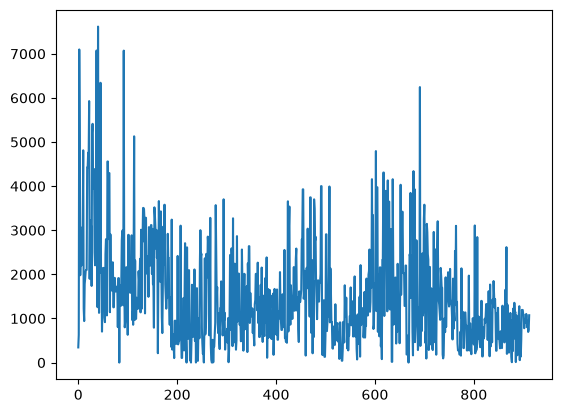

In [13]:
population.plot()

 - записываю данные в файл csv ../../data_additional/population_300.csv

In [14]:
points["population_within_300m"] = population.values
points.drop(columns="geometry").to_csv(OUTPUT_CSV, index=False)
print(f"Готово! Результат сохранён в {OUTPUT_CSV}")
points.drop(columns="geometry").head()

Готово! Результат сохранён в ../../data_additional/population_300.csv


,station_id,station_name,start_lat,start_lng,population_within_300m
0,30200,9th St & Pennsylvania Ave NW,38.894280,-77.023979,343.954590
1,30201,9th & G St NW,38.898097,-77.023924,629.472717
2,31000,Eads St & 15th St S,38.858971,-77.053230,7098.125000
3,31001,18th St & S Eads St,38.857250,-77.053320,5140.592773
4,31002,Crystal Dr & 20th St S,38.856425,-77.049232,1980.399170
